# ResNet-18 + GradMax: Width-Only Growth on CIFAR-10

## What stays unchanged
- CIFAR-10 preprocessing and train/validation/test split.
- `BasicBlock`, convolutional stem, `layer1`–`layer4`, residual connections.
- `AdaptiveAvgPool2d((1, 1))`.
- Cross-entropy loss, SGD with momentum, and cosine learning-rate schedule.

## What changes
- Replace the single `Linear(512, 10)` with `Linear(512, 64) → Tanh → Linear(64, 10)`.
- At selected epochs, add neurons only to the hidden FC layer using GradMax.
- Preserve the existing network function at each growth step and retain SGD momentum for parameters that already existed.

**Kaggle:** Select *Settings → Accelerator → GPU* before running. The notebook automatically selects CUDA when available.

## 1. Imports and configuration

The defaults preserve the original notebook training setup. Growth happens after 4, 8, 12, and 16 completed epochs. You can change the schedule and growth size in this cell.

In [1]:
import os
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# ------------------------- Reproducibility -------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Deterministic settings improve repeatability, with a possible speed cost.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ------------------------- Training setup --------------------------
BATCH_SIZE = 128
EPOCHS = 20
LEARNING_RATE = 0.1
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
TRAIN_FRACTION = 0.9       # 45,000 train / 5,000 validation images
NUM_WORKERS = 2            # Set to 0 if DataLoader workers cause issues

# ------------------------- GradMax setup ---------------------------
INITIAL_HIDDEN_WIDTH = 64
GROWTH_SIZE = 8
# Grow after these many complete epochs; growth occurs before the next epoch.
GROWTH_AFTER_EPOCHS = [4, 8, 12, 16]
# Each new outgoing vector is scaled to the mean L2 norm of existing
# outgoing vectors, following the normalization described in the paper.
GRADMAX_OUTGOING_SCALE = 1.0

DATA_DIR = Path('/kaggle/working/data')
OUTPUT_DIR = Path('/kaggle/working')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Kaggle's standard PyTorch GPU runtime uses CUDA. TPU requires a separate
# torch_xla setup, so this notebook selects CUDA when it is available.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch version:', torch.__version__)
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('CUDA GPU not detected. Training on CPU will be substantially slower.')

assert INITIAL_HIDDEN_WIDTH > 0
assert GROWTH_SIZE > 0
assert all(0 < e < EPOCHS for e in GROWTH_AFTER_EPOCHS)
assert len(set(GROWTH_AFTER_EPOCHS)) == len(GROWTH_AFTER_EPOCHS)
print(f'Initial classifier: 512 -> {INITIAL_HIDDEN_WIDTH} -> 10')
print(f'Growth schedule: {GROWTH_AFTER_EPOCHS}; add {GROWTH_SIZE} neurons per growth step')

PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4
Initial classifier: 512 -> 64 -> 10
Growth schedule: [4, 8, 12, 16]; add 8 neurons per growth step


## 2. Load and prepare CIFAR-10

The train/validation split and augmentation strategy match the original notebook. The official CIFAR-10 test set remains untouched until final evaluation.

In [2]:
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD  = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

train_augmented = datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=True, transform=train_transform
)
train_unaugmented = datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=True, transform=eval_transform
)
test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR), train=False, download=True, transform=eval_transform
)

num_train = len(train_augmented)
num_train_subset = int(TRAIN_FRACTION * num_train)
generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(num_train, generator=generator).tolist()
train_indices = indices[:num_train_subset]
val_indices = indices[num_train_subset:]

train_dataset = Subset(train_augmented, train_indices)
val_dataset = Subset(train_unaugmented, val_indices)

pin_memory = device.type == 'cuda'
loader_kwargs = dict(num_workers=NUM_WORKERS, pin_memory=pin_memory)
if NUM_WORKERS > 0:
    loader_kwargs['persistent_workers'] = True

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    generator=torch.Generator().manual_seed(SEED),
    **loader_kwargs,
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs
)

class_names = train_augmented.classes
print(f'Train: {len(train_dataset):,} | Validation: {len(val_dataset):,} | Test: {len(test_dataset):,}')
print('Classes:', class_names)

100%|██████████| 170M/170M [29:46<00:00, 95.4kB/s]


Train: 45,000 | Validation: 5,000 | Test: 10,000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 3. Inspect a training batch

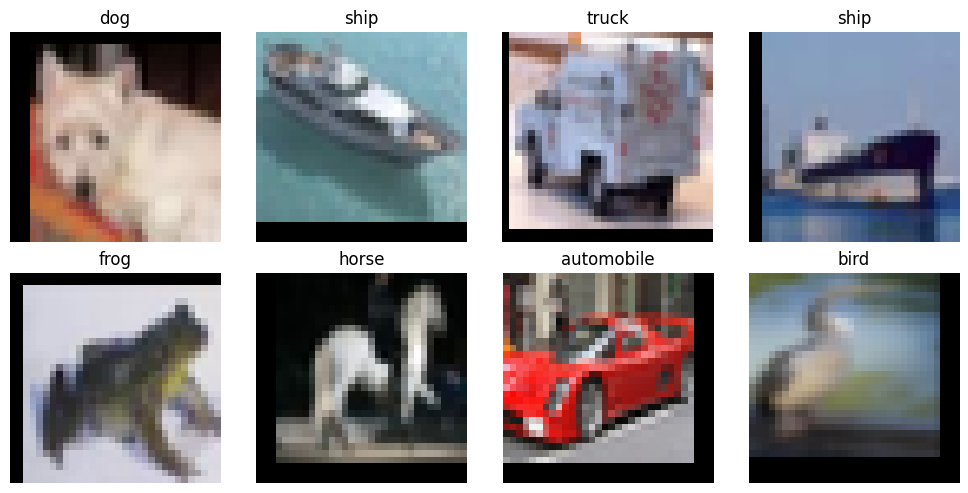

In [3]:
images, labels = next(iter(train_loader))
mean = torch.tensor(CIFAR10_MEAN).view(1, 3, 1, 1)
std = torch.tensor(CIFAR10_STD).view(1, 3, 1, 1)
images_for_plot = (images[:8] * std + mean).clamp(0, 1)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images_for_plot[i].permute(1, 2, 0).cpu().numpy())
    ax.set_title(class_names[int(labels[i])])
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4. ResNet-18 backbone and growing classifier head

The `BasicBlock`, convolutional stem, residual stages, and adaptive average pooling below are unchanged from the original notebook. Only the classifier is different.

After pooling, the backbone returns a 512-dimensional feature vector. The new head is:

$$
h = \tanh(W_1x + b_1)
$$

$$
z = W_2h + b_2
$$

where the hidden width starts at 64 and can increase during training. `Tanh` is used because it satisfies the GradMax derivation's assumptions \(f(0)=0\) and \(f'(0)=1\).

In [4]:
class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(
            in_channels, out_channels, kernel_size=3, stride=stride,
            padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(
            out_channels, out_channels, kernel_size=3, stride=1,
            padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + identity
        out = self.relu(out)
        return out


class ResNet18CIFAR10(nn.Module):
    def __init__(self, num_classes=10, hidden_units=INITIAL_HIDDEN_WIDTH):
        super().__init__()
        self.in_channels = 64
        self.num_classes = num_classes
        self.feature_dim = 512
        self.hidden_width = hidden_units

        # ---------------- Unchanged CIFAR ResNet-18 backbone ----------------
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)

        self.layer1 = self._make_layer(64,  blocks=2, stride=1)
        self.layer2 = self._make_layer(128, blocks=2, stride=2)
        self.layer3 = self._make_layer(256, blocks=2, stride=2)
        self.layer4 = self._make_layer(512, blocks=2, stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        # ---------------- Growing classifier head ----------------
        self.fc1 = nn.Linear(self.feature_dim, hidden_units)
        self.fc2 = nn.Linear(hidden_units, num_classes)

        # Original convolution / BatchNorm initialization is unchanged.
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)

        # Xavier initialization is appropriate for the tanh classifier head.
        nn.init.xavier_uniform_(self.fc1.weight)
        nn.init.zeros_(self.fc1.bias)
        nn.init.xavier_uniform_(self.fc2.weight)
        nn.init.zeros_(self.fc2.bias)

    def _make_layer(self, out_channels, blocks, stride):
        layers = [BasicBlock(self.in_channels, out_channels, stride=stride)]
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(BasicBlock(self.in_channels, out_channels, stride=1))
        return nn.Sequential(*layers)

    def forward_features(self, x):
        # This is the original ResNet-18 convolution + pooling path.
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return x

    def forward(self, x):
        features = self.forward_features(x)
        hidden = torch.tanh(self.fc1(features))
        logits = self.fc2(hidden)
        return logits  # raw logits for CrossEntropyLoss


model = ResNet18CIFAR10(num_classes=10, hidden_units=INITIAL_HIDDEN_WIDTH).to(device)
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f'Trainable parameters: {num_params:,}')

with torch.no_grad():
    dummy_logits = model(torch.zeros(2, 3, 32, 32, device=device))
print('Forward-pass output shape:', tuple(dummy_logits.shape))
assert dummy_logits.shape == (2, 10)
assert model.forward_features(torch.zeros(1, 3, 32, 32, device=device)).shape == (1, 512)

ResNet18CIFAR10(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Identity()
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), st

## 5. Loss, optimizer, scheduler, and checkpoints


In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
    nesterov=False,
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=LEARNING_RATE * 0.01
)

BEST_MODEL_PATH = OUTPUT_DIR / 'resnet18_cifar10_gradmax_best.pth'
LAST_CHECKPOINT_PATH = OUTPUT_DIR / 'resnet18_cifar10_gradmax_last_checkpoint.pth'
HISTORY_PATH = OUTPUT_DIR / 'resnet18_cifar10_gradmax_history.npz'

history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': [], 'lr': [], 'hidden_width': [],
}
best_val_acc = -1.0
print('Best checkpoint path:', BEST_MODEL_PATH)

Best checkpoint path: /kaggle/working/resnet18_cifar10_gradmax_best.pth


## 6. GradMax Width-Growth Implementation

At a growth step, suppose the classifier is currently `512 → H → 10`. We add `k` hidden neurons.

1. **Initialize the new neurons:** Set the new incoming rows and hidden biases to zero. With `Tanh`, each new activation is initially zero, so the classifier's logits remain unchanged.

2. **Introduce an auxiliary linear map:** Temporarily add a zero auxiliary linear map from the 512-dimensional pooled feature vector directly to the 10 logits. Its gradient is:

   $$
   G = \frac{\partial L}{\partial W_{\text{aux}}}
   = \frac{1}{B}\sum_{i=1}^{B}
   \frac{\partial L_i}{\partial z_i}x_i^T
   \in \mathbb{R}^{10 \times 512}
   $$

3. **Perform Singular Value Decomposition (SVD):** Compute:

   $$
   G = U\Sigma V^T
   $$

   The columns of \(U\) corresponding to the largest singular values initialize the new outgoing connections.

4. **Expand the classifier:** Expand `fc1.weight`, `fc1.bias`, and `fc2.weight`. Leave the output bias unchanged.

5. **Verify functional equivalence:** Verify that the logits before and after growth match to numerical precision.

**Implementation Notes:**

- The SVD is estimated from one training minibatch, matching the paper's minibatch approximation idea.
- For this head-only adaptation, the SVD matrix is only `10 × 512`, so the decomposition is inexpensive.
- The growth size must not exceed 10 because there are only 10 left-singular vectors in this matrix.

In [6]:
def _pad_state_tensor(tensor, dim, amount):
    """Append zero entries to an optimizer state tensor along one dimension."""
    if not torch.is_tensor(tensor) or tensor.ndim == 0:
        return tensor
    pad_shape = list(tensor.shape)
    pad_shape[dim] = amount
    padding = tensor.new_zeros(pad_shape)
    return torch.cat([tensor, padding], dim=dim)


def _replace_parameter_in_optimizer(optimizer, old_param, new_param, state_pad_dim=None, pad_amount=0):
    """Replace a Parameter in optimizer groups and migrate its state (e.g. SGD momentum)."""
    found = False
    for group in optimizer.param_groups:
        for index, param in enumerate(group['params']):
            if param is old_param:
                group['params'][index] = new_param
                found = True

    if not found:
        raise RuntimeError('Could not find an expanded parameter in the optimizer.')

    old_state = optimizer.state.pop(old_param, {})
    if old_state:
        new_state = {}
        for key, value in old_state.items():
            if (
                torch.is_tensor(value)
                and value.shape == old_param.shape
                and state_pad_dim is not None
            ):
                new_state[key] = _pad_state_tensor(value, state_pad_dim, pad_amount)
            else:
                new_state[key] = value
        optimizer.state[new_param] = new_state


def gradmax_grow_hidden_layer(
    model,
    optimizer,
    growth_inputs,
    growth_targets,
    criterion,
    growth_size=GROWTH_SIZE,
    outgoing_scale=GRADMAX_OUTGOING_SCALE,
):
    """Add hidden units to the FC head using the GradMax SVD initialization.

    The convolutional backbone and pooling layer are not modified.
    Existing SGD momentum buffers are preserved for all old parameters.
    """
    if growth_size <= 0:
        raise ValueError('growth_size must be positive.')

    old_width = model.hidden_width
    growth_size = min(growth_size, model.num_classes)

    growth_inputs = growth_inputs.to(device, non_blocking=(device.type == 'cuda'))
    growth_targets = growth_targets.to(device, non_blocking=(device.type == 'cuda'))

    # Capture BatchNorm buffers. We use training-batch statistics to estimate G,
    # but restore the buffers afterwards so this extra pass does not alter the backbone.
    was_training = model.training
    bn_snapshot = []
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            bn_snapshot.append((
                module,
                None if module.running_mean is None else module.running_mean.detach().clone(),
                None if module.running_var is None else module.running_var.detach().clone(),
                None if module.num_batches_tracked is None else module.num_batches_tracked.detach().clone(),
            ))

    model.train()
    try:
        with torch.no_grad():
            features = model.forward_features(growth_inputs).detach()
    finally:
        # Restore BatchNorm buffers exactly after the extra feature-extraction pass.
        for module, running_mean, running_var, num_batches in bn_snapshot:
            if running_mean is not None:
                module.running_mean.copy_(running_mean)
            if running_var is not None:
                module.running_var.copy_(running_var)
            if num_batches is not None:
                module.num_batches_tracked.copy_(num_batches)
        model.train(was_training)

    # Auxiliary zero map: logits_aux = W_aux @ features. Its gradient is G.
    with torch.enable_grad():
        hidden = torch.tanh(model.fc1(features))
        current_logits = model.fc2(hidden)
        auxiliary_weight = torch.zeros(
            model.num_classes,
            model.feature_dim,
            device=features.device,
            dtype=features.dtype,
            requires_grad=True,
        )
        auxiliary_logits = F.linear(features, auxiliary_weight)
        growth_loss = criterion(current_logits + auxiliary_logits, growth_targets)
        grad_matrix = torch.autograd.grad(growth_loss, auxiliary_weight, retain_graph=False)[0]

    grad_matrix = grad_matrix.detach().float()
    if not torch.isfinite(grad_matrix).all():
        raise RuntimeError('GradMax gradient matrix contains NaN or Inf values.')
    grad_norm = torch.linalg.vector_norm(grad_matrix)
    if grad_norm.item() < 1e-12:
        raise RuntimeError('GradMax gradient matrix is approximately zero; cannot derive useful SVD directions.')

    # G has shape [num_classes, feature_dim]. The left singular vectors are
    # output-space directions and become columns of the new fc2 weights.
    U, singular_values, Vh = torch.linalg.svd(grad_matrix, full_matrices=False)
    k = min(growth_size, U.shape[1])
    new_outgoing = U[:, :k]

    # Match the average outgoing-vector norm of the existing hidden neurons.
    existing_outgoing_norm = torch.linalg.vector_norm(
        model.fc2.weight.detach(), ord=2, dim=0
    ).mean()
    scale = existing_outgoing_norm * outgoing_scale
    new_outgoing = (new_outgoing * scale).to(dtype=model.fc2.weight.dtype)

    # Confirm function preservation before changing the parameters.
    check_inputs = growth_inputs[:min(16, growth_inputs.size(0))]
    model.eval()
    with torch.no_grad():
        logits_before = model(check_inputs).detach().clone()

    old_fc1_weight = model.fc1.weight
    old_fc1_bias = model.fc1.bias
    old_fc2_weight = model.fc2.weight

    new_fc1_weight = nn.Parameter(torch.cat([
        old_fc1_weight.detach(),
        old_fc1_weight.new_zeros((k, model.feature_dim)),
    ], dim=0))
    new_fc1_bias = nn.Parameter(torch.cat([
        old_fc1_bias.detach(),
        old_fc1_bias.new_zeros(k),
    ], dim=0))
    new_fc2_weight = nn.Parameter(torch.cat([
        old_fc2_weight.detach(),
        new_outgoing,
    ], dim=1))

    # Replace FC parameters on the model.
    model.fc1.weight = new_fc1_weight
    model.fc1.bias = new_fc1_bias
    model.fc2.weight = new_fc2_weight
    model.hidden_width = old_width + k

    # Keep old momentum buffers; append zeros for newly created parameter entries.
    _replace_parameter_in_optimizer(
        optimizer, old_fc1_weight, new_fc1_weight, state_pad_dim=0, pad_amount=k
    )
    _replace_parameter_in_optimizer(
        optimizer, old_fc1_bias, new_fc1_bias, state_pad_dim=0, pad_amount=k
    )
    _replace_parameter_in_optimizer(
        optimizer, old_fc2_weight, new_fc2_weight, state_pad_dim=1, pad_amount=k
    )

    with torch.no_grad():
        logits_after = model(check_inputs).detach()
    max_logit_difference = (logits_before - logits_after).abs().max().item()
    model.train(was_training)

    if max_logit_difference > 1e-5:
        raise RuntimeError(
            f'Growth was not function-preserving: max logit difference = {max_logit_difference:.3e}'
        )

    return {
        'old_width': old_width,
        'new_width': model.hidden_width,
        'added': k,
        'gradient_norm': grad_norm.item(),
        'top_singular_values': singular_values[:k].detach().cpu().tolist(),
        'outgoing_vector_scale': float(scale.item()),
        'max_logit_difference': max_logit_difference,
    }


# A small sanity check for the mathematical constraint.
assert torch.tanh(torch.tensor(0.0)).item() == 0.0
print('GradMax growth functions are ready.')

GradMax growth functions are ready.


## 7. Training loop with scheduled width growth

Growth is performed **before** the epoch following each milestone in `GROWTH_AFTER_EPOCHS`. For example, when the schedule contains `4`, the first growth occurs after four complete epochs and before epoch 5.

At each growth event we use one minibatch from the augmented training loader to estimate the GradMax SVD matrix. The training loop then continues with the expanded head. The optimizer's existing momentum is retained.

In [7]:
def run_one_epoch(model, loader, criterion, optimizer=None, device=device):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    context = torch.enable_grad() if is_training else torch.no_grad()
    with context:
        for inputs, targets in loader:
            inputs = inputs.to(device, non_blocking=(device.type == 'cuda'))
            targets = targets.to(device, non_blocking=(device.type == 'cuda'))

            if is_training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(inputs)
            loss = criterion(logits, targets)

            if is_training:
                loss.backward()
                optimizer.step()

            batch_size = targets.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == targets).sum().item()
            total_examples += batch_size

    return total_loss / total_examples, total_correct / total_examples


for epoch in range(EPOCHS):
    # Growth milestones are counts of completed epochs (1-based values in the config).
    completed_epochs = epoch
    if completed_epochs in GROWTH_AFTER_EPOCHS:
        growth_inputs, growth_targets = next(iter(train_loader))
        growth_info = gradmax_grow_hidden_layer(
            model=model,
            optimizer=optimizer,
            growth_inputs=growth_inputs,
            growth_targets=growth_targets,
            criterion=criterion,
            growth_size=GROWTH_SIZE,
        )
        print(
            f"\n[GradMax] After epoch {completed_epochs}: "
            f"hidden width {growth_info['old_width']} -> {growth_info['new_width']} "
            f"(added {growth_info['added']}) | "
            f"||G||_F={growth_info['gradient_norm']:.4e} | "
            f"max |logit_before - logit_after|={growth_info['max_logit_difference']:.3e}"
        )
        print('Top singular values:', [round(v, 6) for v in growth_info['top_singular_values']])

    epoch_start = time.time()
    current_lr = optimizer.param_groups[0]['lr']

    train_loss, train_acc = run_one_epoch(model, train_loader, criterion, optimizer=optimizer)
    val_loss, val_acc = run_one_epoch(model, val_loader, criterion, optimizer=None)
    scheduler.step()

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['lr'].append(current_lr)
    history['hidden_width'].append(model.hidden_width)

    checkpoint_payload = {
        'epoch': epoch + 1,
        'hidden_width': model.hidden_width,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'best_val_acc': max(best_val_acc, val_acc),
        'class_names': class_names,
        'seed': SEED,
        'growth_after_epochs': GROWTH_AFTER_EPOCHS,
        'growth_size': GROWTH_SIZE,
    }

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        checkpoint_payload['best_val_acc'] = best_val_acc
        torch.save(checkpoint_payload, BEST_MODEL_PATH)
        best_marker = '  * best checkpoint saved'
    else:
        best_marker = ''

    checkpoint_payload['best_val_acc'] = best_val_acc
    torch.save(checkpoint_payload, LAST_CHECKPOINT_PATH)
    np.savez(HISTORY_PATH, **{k: np.asarray(v) for k, v in history.items()})

    elapsed = time.time() - epoch_start
    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | width={model.hidden_width:3d} | "
        f"lr={current_lr:.5f} | "
        f"train loss={train_loss:.4f}, acc={train_acc * 100:.2f}% | "
        f"val loss={val_loss:.4f}, acc={val_acc * 100:.2f}% | "
        f"{elapsed:.1f}s{best_marker}"
    )

print(f'\nBest validation accuracy: {best_val_acc * 100:.2f}%')
print('Best model saved to:', BEST_MODEL_PATH)
print('Last checkpoint saved to:', LAST_CHECKPOINT_PATH)
print('Final training hidden width:', model.hidden_width)

Epoch 01/20 | width= 64 | lr=0.10000 | train loss=1.9049, acc=29.14% | val loss=1.8347, acc=31.82% | 47.8s  * best checkpoint saved
Epoch 02/20 | width= 64 | lr=0.09939 | train loss=1.5301, acc=44.04% | val loss=1.5213, acc=43.98% | 50.6s  * best checkpoint saved
Epoch 03/20 | width= 64 | lr=0.09758 | train loss=1.2204, acc=56.81% | val loss=1.4542, acc=50.60% | 56.2s  * best checkpoint saved
Epoch 04/20 | width= 64 | lr=0.09460 | train loss=0.9641, acc=66.16% | val loss=0.8741, acc=69.00% | 59.8s  * best checkpoint saved

[GradMax] After epoch 4: hidden width 64 -> 72 (added 8) | ||G||_F=4.1711e-01 | max |logit_before - logit_after|=0.000e+00
Top singular values: [0.366927, 0.133691, 0.093583, 0.069727, 0.059506, 0.045291, 0.034118, 0.028084]
Epoch 05/20 | width= 72 | lr=0.09055 | train loss=0.7772, acc=73.13% | val loss=1.1022, acc=64.18% | 59.4s
Epoch 06/20 | width= 72 | lr=0.08550 | train loss=0.6685, acc=76.96% | val loss=0.6835, acc=76.22% | 59.2s  * best checkpoint saved
Epoch 0

## 8. Learning curves and width schedule

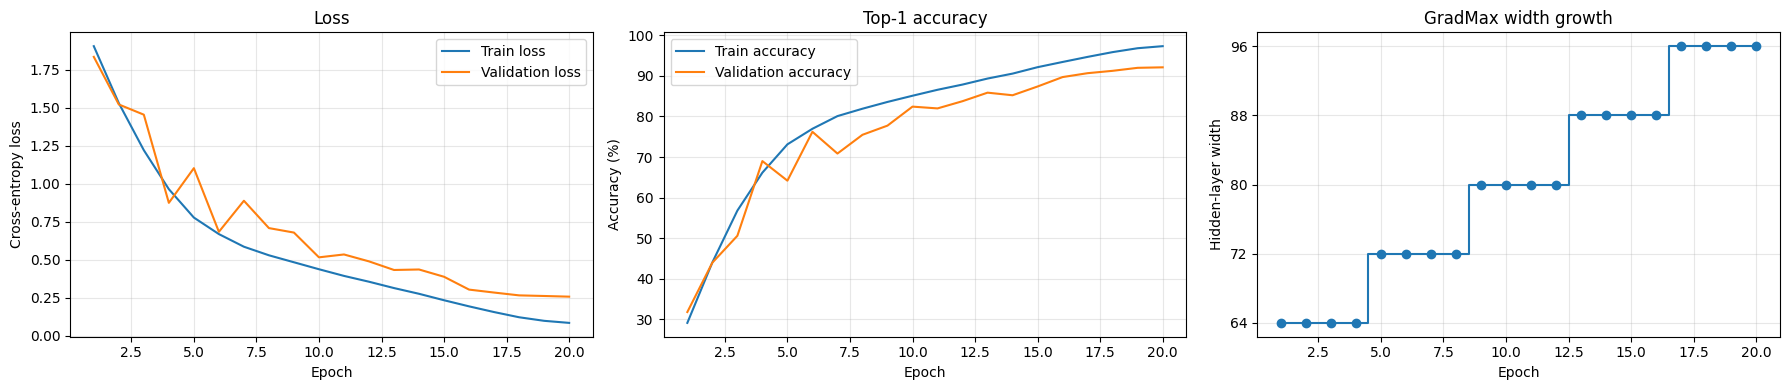

In [8]:
epochs_axis = np.arange(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(epochs_axis, history['train_loss'], label='Train loss')
axes[0].plot(epochs_axis, history['val_loss'], label='Validation loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].set_title('Loss')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(epochs_axis, np.array(history['train_acc']) * 100, label='Train accuracy')
axes[1].plot(epochs_axis, np.array(history['val_acc']) * 100, label='Validation accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Top-1 accuracy')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

axes[2].step(epochs_axis, history['hidden_width'], where='mid', marker='o')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Hidden-layer width')
axes[2].set_title('GradMax width growth')
axes[2].set_yticks(sorted(set(history['hidden_width'])))
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Final test-set evaluation

The best checkpoint may come from an epoch before or after a growth event, so its `hidden_width` metadata is used to instantiate a model with the matching head shape before loading the state dictionary. The official CIFAR-10 test set is evaluated only here.

In [9]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
best_hidden_width = int(checkpoint['hidden_width'])

best_model = ResNet18CIFAR10(
    num_classes=10,
    hidden_units=best_hidden_width,
).to(device)
best_model.load_state_dict(checkpoint['model_state_dict'])
best_model.eval()

test_loss, test_acc = run_one_epoch(
    best_model, test_loader, criterion, optimizer=None
)
print('Best checkpoint epoch:', checkpoint['epoch'])
print('Best checkpoint hidden width:', best_hidden_width)
print(f"Best validation accuracy: {checkpoint['best_val_acc'] * 100:.2f}%")
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_acc * 100:.2f}%')

Best checkpoint epoch: 20
Best checkpoint hidden width: 96
Best validation accuracy: 92.10%
Test loss: 0.2558
Test accuracy: 91.84%


## 10. Per-class test accuracy

In [10]:
correct_by_class = torch.zeros(10, dtype=torch.long)
total_by_class = torch.zeros(10, dtype=torch.long)

best_model.eval()
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device, non_blocking=(device.type == 'cuda'))
        targets = targets.to(device, non_blocking=(device.type == 'cuda'))
        predictions = best_model(inputs).argmax(dim=1)
        for class_id in range(10):
            mask = (targets == class_id)
            total_by_class[class_id] += mask.sum().cpu()
            correct_by_class[class_id] += ((predictions == targets) & mask).sum().cpu()

for class_id, name in enumerate(class_names):
    denom = int(total_by_class[class_id])
    class_acc = 100.0 * int(correct_by_class[class_id]) / max(denom, 1)
    print(f'{name:>10s}: {class_acc:6.2f}% ({int(correct_by_class[class_id])}/{denom})')

  airplane:  92.90% (929/1000)
automobile:  96.60% (966/1000)
      bird:  88.90% (889/1000)
       cat:  81.20% (812/1000)
      deer:  92.20% (922/1000)
       dog:  88.10% (881/1000)
      frog:  94.40% (944/1000)
     horse:  93.60% (936/1000)
      ship:  95.80% (958/1000)
     truck:  94.70% (947/1000)


## 11. Visualize predictions

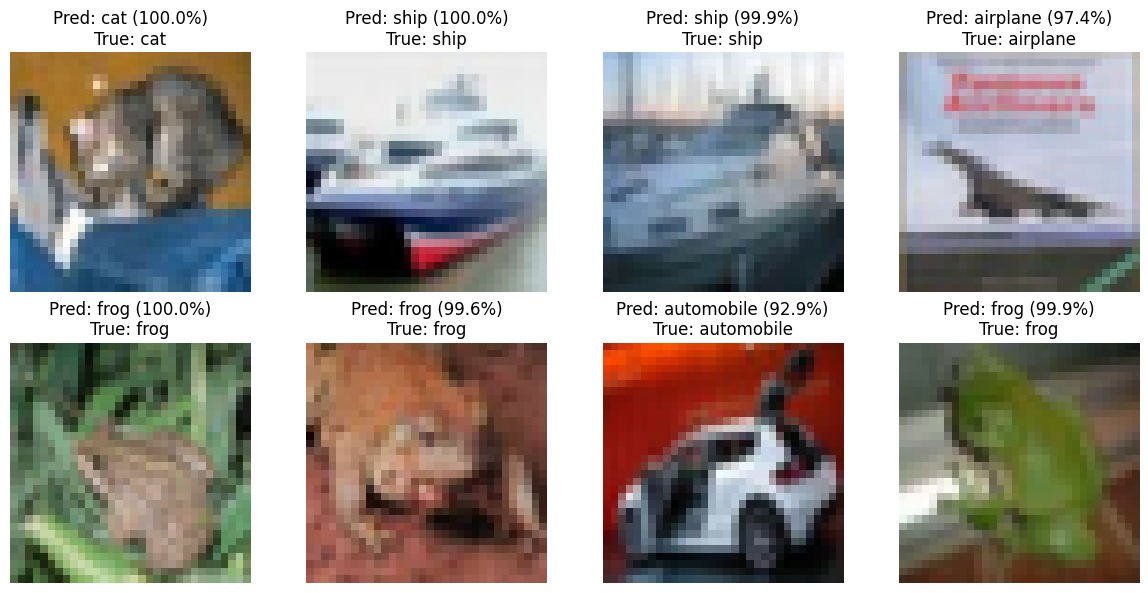

In [11]:
images, labels = next(iter(test_loader))
best_model.eval()
with torch.no_grad():
    logits = best_model(images.to(device))
    probabilities = torch.softmax(logits, dim=1).cpu()
    predictions = probabilities.argmax(dim=1)

images_for_plot = (images[:8] * std + mean).clamp(0, 1)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(images_for_plot[i].permute(1, 2, 0).numpy())
    true_name = class_names[int(labels[i])]
    pred_name = class_names[int(predictions[i])]
    confidence = float(probabilities[i, predictions[i]]) * 100
    ax.set_title(f'Pred: {pred_name} ({confidence:.1f}%)\nTrue: {true_name}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 12. Save the best GradMax model

The saved file includes the state dictionary and the selected hidden width. This width metadata is necessary because the classifier architecture changes during training.

In [12]:
WEIGHTS_PATH = OUTPUT_DIR / 'resnet18_cifar10_gradmax_weights.pth'
WEIGHTS_PATH_INFO = {
    'model_state_dict': best_model.state_dict(),
    'hidden_width': best_hidden_width,
    'num_classes': 10,
    'feature_dim': 512,
    'class_names': class_names,
}
torch.save(WEIGHTS_PATH_INFO, WEIGHTS_PATH)

print('Saved model:', WEIGHTS_PATH)
for path in [BEST_MODEL_PATH, LAST_CHECKPOINT_PATH, HISTORY_PATH, WEIGHTS_PATH]:
    if path.exists():
        print(f'{path.name:48s} {path.stat().st_size / (1024 * 1024):.2f} MiB')

# Example inference-time loading:
# saved = torch.load(WEIGHTS_PATH, map_location='cpu')
# inference_model = ResNet18CIFAR10(
#     num_classes=saved['num_classes'], hidden_units=saved['hidden_width']
# )
# inference_model.load_state_dict(saved['model_state_dict'])
# inference_model.eval()

Saved model: /kaggle/working/resnet18_cifar10_gradmax_weights.pth
resnet18_cifar10_gradmax_best.pth                85.69 MiB
resnet18_cifar10_gradmax_last_checkpoint.pth     85.70 MiB
resnet18_cifar10_gradmax_history.npz             0.00 MiB
resnet18_cifar10_gradmax_weights.pth             42.88 MiB


## 13. Interpretation and research notes

1. **Function-preserving growth:** At each growth step, new incoming weights and biases are zero and `Tanh(0) = 0`. The code checks the maximum absolute logit difference before and after growth and raises an error if it exceeds `1e-5`.
2. **What is optimized by GradMax:** SVD selects outgoing directions that maximize the gradient norm of the newly added incoming weights under the paper's approximation. This does not guarantee higher test accuracy.
3. **This is width-only growth:** The hidden width changes, but the number of layers stays fixed. No convolution, residual block, pooling operation, or output class is added or changed.
4. **Head-only adaptation:** The original paper's CIFAR experiments grow convolutional layers in Wide-ResNet. Applying its fully connected derivation only to this ResNet classifier head is a new experimental variant.
5. **Fair comparison:** Compare this run against (a) your original `512 → 10` baseline and (b) a fixed-width `512 → 96 → 10` MLP trained with the same split, epochs, augmentations, and optimizer. These comparisons separate the effect of the MLP head from the effect of GradMax growth.
6. **Reproducibility:** Run multiple seeds and report mean and standard deviation. Accuracy can vary with random initialization and data order.

### Expected architecture during this run

| Training phase | Classifier head |
|---|---|
| Initial | 512 → 64 → 10 |
| After 4 epochs | 512 → 72 → 10 |
| After 8 epochs | 512 → 80 → 10 |
| After 12 epochs | 512 → 88 → 10 |
| After 16 epochs | 512 → 96 → 10 |
